<a href="https://colab.research.google.com/github/moazmohemeda-boop/autism_vit/blob/main/autism_vit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import kagglehub
prayashdas_autistic_children_facial_image_dataset_path = kagglehub.dataset_download('prayashdas/autistic-children-facial-image-dataset')
keras_vit_keras_vit_base_patch16_224_imagenet21k_3_path = kagglehub.model_download('keras/vit/Keras/vit_base_patch16_224_imagenet21k/3')

print('Data source import complete.')


In [ ]:
# %% [1]
!pip -q install -U keras-hub

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
import keras_hub

from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

keras.mixed_precision.set_global_policy("mixed_float16")

BASE_DIR = "/kaggle/input/datasets/prayashdas/autistic-children-facial-image-dataset"

TRAIN_DIR = os.path.join(BASE_DIR, "train")
VAL_DIR = os.path.join(BASE_DIR, "valid")
TEST_DIR = os.path.join(BASE_DIR, "test")

LABELS = {"non_autistic": 0, "autistic": 1}
IMG_SIZE = 224
BATCH_SIZE = 16

def get_dataframe(folder):
    rows = []

    for class_name, label in LABELS.items():
        class_dir = os.path.join(folder, class_name)

        for filename in os.listdir(class_dir):
            if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                rows.append({
                    "path": os.path.join(class_dir, filename),
                    "label": label
                })

    return pd.DataFrame(rows).sample(
        frac=1, random_state=SEED
    ).reset_index(drop=True)

train_df = get_dataframe(TRAIN_DIR)
val_df = get_dataframe(VAL_DIR)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("\nTraining distribution:")
print(train_df["label"].value_counts())
print("\nValidation distribution:")
print(val_df["label"].value_counts())

assert set(train_df["label"].unique()) == {0, 1}
assert set(val_df["label"].unique()) == {0, 1}

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 32.9 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 82.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.32.0 which is incompatible.
Training: 2526
Validation: 200

Training distribution:
label
1    1263
0    1263
Name: count, dtype: int64

Validation distribution:
label
0    100
1    100
Name: count, dtype: int64


In [ ]:
# %% [2]
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label, training=False):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image, [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32)

    if training:
        image = tf.image.random_flip_left_right(image)

        image = tf.image.random_brightness(
            image, max_delta=8.0
        )

        image = tf.image.random_contrast(
            image, lower=0.9, upper=1.1
        )

    image = tf.clip_by_value(image, 0.0, 255.0)

    # ViT preprocessing
    image = image / 127.5 - 1.0

    label = tf.cast(label, tf.float32)

    return image, label


def make_dataset(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        df["path"].values,
        df["label"].values.astype("float32")
    ))

    if training:
        ds = ds.shuffle(
            len(df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        lambda x, y: load_image(x, y, training),
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)

I0000 00:00:1791775515.600760      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791775515.604245      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [ ]:
# %% [3]
inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3)
)

backbone = keras_hub.models.ViTBackbone.from_preset(
    "vit_base_patch16_224_imagenet21k"
)

backbone.trainable = False

features = backbone(inputs)
features = features[:, 0, :]

x = keras.layers.Dropout(0.2)(features)

outputs = keras.layers.Dense(
    1,
    activation="sigmoid",
    dtype="float32"
)(x)

model = keras.Model(inputs, outputs)

def compile_model(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.AdamW(
            learning_rate=learning_rate,
            weight_decay=1e-4
        ),
        loss=keras.losses.BinaryCrossentropy(
            label_smoothing=0.05
        ),
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="auc")
        ]
    )


compile_model(model, 1e-3)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vi_t_backbone (ViTBackbone)     │ (None, 197, 768)       │    85,798,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ get_item (GetItem)              │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           769 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 85,799,425 (327.30 MB)

 Trainable params: 769 (3.00 KB)

 Non-trainable params: 85,798,656 (327.30 MB)

In [ ]:
# %% [4]
callbacks_head = [
    keras.callbacks.ModelCheckpoint(
        "/kaggle/working/vit_head.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks_head
)

Epoch 1/8


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  2/158 ━━━━━━━━━━━━━━━━━━━━ 10s 67ms/step - accuracy: 0.5625 - auc: 0.6255 - loss: 0.6811 

I0000 00:00:1791775543.412760     137 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.6754 - auc: 0.7561 - loss: 0.6143
Epoch 1: val_loss improved from None to 0.55814, saving model to /kaggle/working/vit_head.keras

Epoch 1: finished saving model to /kaggle/working/vit_head.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 40s 146ms/step - accuracy: 0.6754 - auc: 0.7561 - loss: 0.6143 - val_accuracy: 0.7650 - val_auc: 0.8424 - val_loss: 0.5581 - learning_rate: 0.0010
Epoch 2/8
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.7767 - auc: 0.8569 - loss: 0.5268
Epoch 2: val_loss improved from 0.55814 to 0.51468, saving model to /kaggle/working/vit_head.keras

Epoch 2: finished saving model to /kaggle/working/vit_head.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 0.7767 - auc: 0.8569 - loss: 0.5268 - val_accuracy: 0.8200 - val_auc: 0.8618 - val_loss: 0.5147 - learning_rate: 0.0010
Epoch 3/8
157/158 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.7894 - auc: 0.8739 - loss: 0.4948
Epoch 3: val_loss improved from 

In [ ]:
# %% [5]
model = keras.models.load_model(
    "/kaggle/working/vit_head.keras"
)

backbone = model.get_layer(
    backbone.name
)

backbone.trainable = True

compile_model(model, 1e-5)

callbacks_finetune = [
    keras.callbacks.ModelCheckpoint(
        "/kaggle/working/vit_finetuned.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks_finetune
)

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 406 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)
/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_w', because it has 402 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(store)


158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 286ms/step - accuracy: 0.8456 - auc: 0.9210 - loss: 0.4025
Epoch 1: val_loss improved from None to 0.39936, saving model to /kaggle/working/vit_finetuned.keras

Epoch 1: finished saving model to /kaggle/working/vit_finetuned.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 112s 378ms/step - accuracy: 0.8456 - auc: 0.9210 - loss: 0.4025 - val_accuracy: 0.8450 - val_auc: 0.9346 - val_loss: 0.3994 - learning_rate: 1.0000e-05
Epoch 2/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - accuracy: 0.9192 - auc: 0.9713 - loss: 0.2937
Epoch 2: val_loss improved from 0.39936 to 0.37056, saving model to /kaggle/working/vit_finetuned.keras

Epoch 2: finished saving model to /kaggle/working/vit_finetuned.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 32s 204ms/step - accuracy: 0.9192 - auc: 0.9713 - loss: 0.2937 - val_accuracy: 0.8600 - val_auc: 0.9472 - val_loss: 0.3706 - learning_rate: 1.0000e-05
Epoch 3/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.9608 - auc: 0.9923 - loss: 0.21

In [ ]:
# %% [6]
model = keras.models.load_model(
    "/kaggle/working/vit_finetuned.keras"
)

val_results = model.evaluate(
    val_ds,
    return_dict=True,
    verbose=1
)

print("Validation results:", val_results)

13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 260ms/step - accuracy: 0.8850 - auc: 0.9598 - loss: 0.3307
Validation results: {'accuracy': 0.8849999904632568, 'auc': 0.9598000049591064, 'loss': 0.33074820041656494}


In [ ]:
# %% [7]
test_df = get_dataframe(TEST_DIR)

test_ds = make_dataset(
    test_df,
    training=False
)

y_true = test_df["label"].to_numpy()

# Original images
p1 = model.predict(test_ds, verbose=1).ravel()

# Horizontal flip TTA
flip_ds = test_ds.map(
    lambda x, y: (tf.image.flip_left_right(x), y),
    num_parallel_calls=AUTOTUNE
)

p2 = model.predict(flip_ds, verbose=1).ravel()

# Fixed TTA rule
y_prob = (p1 + p2) / 2.0

# Fixed threshold; not tuned on test
y_pred = (y_prob >= 0.5).astype(int)

print("Test Accuracy:", np.mean(y_true == y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["non_autistic", "autistic"],
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 386ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step
Test Accuracy: 0.925

Classification Report:
              precision    recall  f1-score   support

non_autistic     0.9208    0.9300    0.9254       100
    autistic     0.9293    0.9200    0.9246       100

    accuracy                         0.9250       200
   macro avg     0.9250    0.9250    0.9250       200
weighted avg     0.9250    0.9250    0.9250       200


Confusion Matrix:
[[93  7]
 [ 8 92]]


In [ ]:
# %% Cell 12: Additional Fine-Tuning Experiment

import keras

# Load the current best model
baseline_model = keras.models.load_model(
    "/kaggle/working/vit_finetuned.keras"
)

# Find the ViT backbone by its actual layer name
backbone_layer = baseline_model.get_layer("vi_t_backbone")

# Unfreeze the backbone
backbone_layer.trainable = True

# Compile with a very low learning rate
baseline_model.compile(
    optimizer=keras.optimizers.AdamW(
        learning_rate=2e-6,
        weight_decay=1e-4
    ),
    loss=keras.losses.BinaryCrossentropy(
        label_smoothing=0.05
    ),
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        "/kaggle/working/vit_extra_finetuned.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

# Continue training using the existing datasets
history_extra = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)

# Load the best saved checkpoint
extra_model = keras.models.load_model(
    "/kaggle/working/vit_extra_finetuned.keras"
)

# Evaluate on validation only
val_results = extra_model.evaluate(
    val_ds,
    verbose=1,
    return_dict=True
)

print("\nAdditional fine-tuning validation results:")
print(val_results)

Epoch 1/8


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step - accuracy: 0.9960 - auc: 0.9997 - loss: 0.1474
Epoch 1: val_loss improved from None to 0.33470, saving model to /kaggle/working/vit_extra_finetuned.keras

Epoch 1: finished saving model to /kaggle/working/vit_extra_finetuned.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 109s 367ms/step - accuracy: 0.9960 - auc: 0.9997 - loss: 0.1474 - val_accuracy: 0.8900 - val_auc: 0.9549 - val_loss: 0.3347 - learning_rate: 2.0000e-06
Epoch 2/8
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.9964 - auc: 0.9999 - loss: 0.1410
Epoch 2: val_loss improved from 0.33470 to 0.33367, saving model to /kaggle/working/vit_extra_finetuned.keras

Epoch 2: finished saving model to /kaggle/working/vit_extra_finetuned.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 33s 207ms/step - accuracy: 0.9964 - auc: 0.9999 - loss: 0.1410 - val_accuracy: 0.8900 - val_auc: 0.9534 - val_loss: 0.3337 - learning_rate: 2.0000e-06
Epoch 3/8
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.9984 - au

In [ ]:
# %% Cell 13: Compare Baseline vs Extra Fine-Tuned ViT

import numpy as np
import keras
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Load both saved models
baseline_model = keras.models.load_model(
    "/kaggle/working/vit_finetuned.keras"
)

extra_model = keras.models.load_model(
    "/kaggle/working/vit_extra_finetuned.keras"
)

# Predict on the same validation dataset
def get_predictions(model, dataset):
    y_true = []
    y_prob = []

    for images, labels in dataset:
        probs = model.predict(images, verbose=0).reshape(-1)
        y_prob.extend(probs)
        y_true.extend(labels.numpy().reshape(-1))

    return np.array(y_true).astype(int), np.array(y_prob)

y_true, baseline_probs = get_predictions(
    baseline_model, val_ds
)

_, extra_probs = get_predictions(
    extra_model, val_ds
)

# Compare both models at threshold 0.5
for name, probs in [
    ("Baseline ViT", baseline_probs),
    ("Extra Fine-Tuned ViT", extra_probs)
]:
    predictions = (probs >= 0.5).astype(int)

    print(f"\n{'=' * 45}")
    print(name)
    print("=" * 45)

    print("Accuracy:", round(
        accuracy_score(y_true, predictions), 4
    ))

    print("AUC:", round(
        roc_auc_score(y_true, probs), 4
    ))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        predictions,
        target_names=["non_autistic", "autistic"],
        digits=4
    ))

# Compare thresholds on validation only
print("\nThreshold comparison on validation:")

for threshold in [0.50, 0.55, 0.60, 0.625, 0.65, 0.675, 0.70]:
    baseline_acc = accuracy_score(
        y_true, (baseline_probs >= threshold).astype(int)
    )
    extra_acc = accuracy_score(
        y_true, (extra_probs >= threshold).astype(int)
    )

    print(
        f"Threshold={threshold:.3f} | "
        f"Baseline={baseline_acc:.3f} | "
        f"Extra Fine-Tuned={extra_acc:.3f}"
    )


Baseline ViT
Accuracy: 0.885
AUC: 0.9597

Confusion Matrix:
[[85 15]
 [ 8 92]]

Classification Report:
              precision    recall  f1-score   support

non_autistic     0.9140    0.8500    0.8808       100
    autistic     0.8598    0.9200    0.8889       100

    accuracy                         0.8850       200
   macro avg     0.8869    0.8850    0.8849       200
weighted avg     0.8869    0.8850    0.8849       200


Extra Fine-Tuned ViT
Accuracy: 0.89
AUC: 0.9532

Confusion Matrix:
[[88 12]
 [10 90]]

Classification Report:
              precision    recall  f1-score   support

non_autistic     0.8980    0.8800    0.8889       100
    autistic     0.8824    0.9000    0.8911       100

    accuracy                         0.8900       200
   macro avg     0.8902    0.8900    0.8900       200
weighted avg     0.8902    0.8900    0.8900       200


Threshold comparison on validation:
Threshold=0.500 | Baseline=0.885 | Extra Fine-Tuned=0.890
Threshold=0.550 | Baseline=0.890 | E

7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 776ms/step
Validation images: 200
Incorrect predictions: 23
Accuracy: 0.885

Confusion Matrix:
[[85 15]
 [ 8 92]]


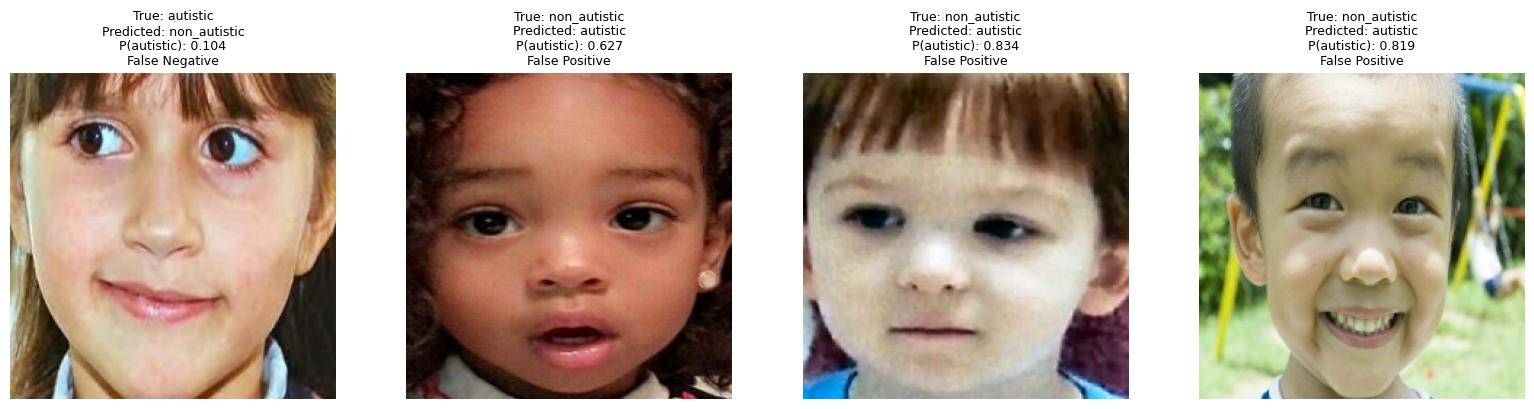

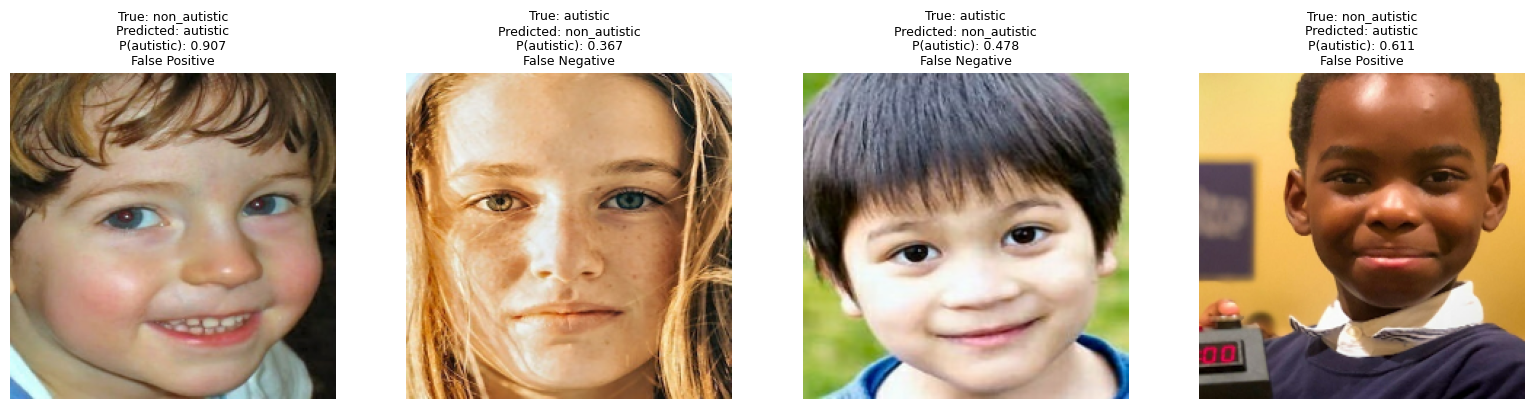

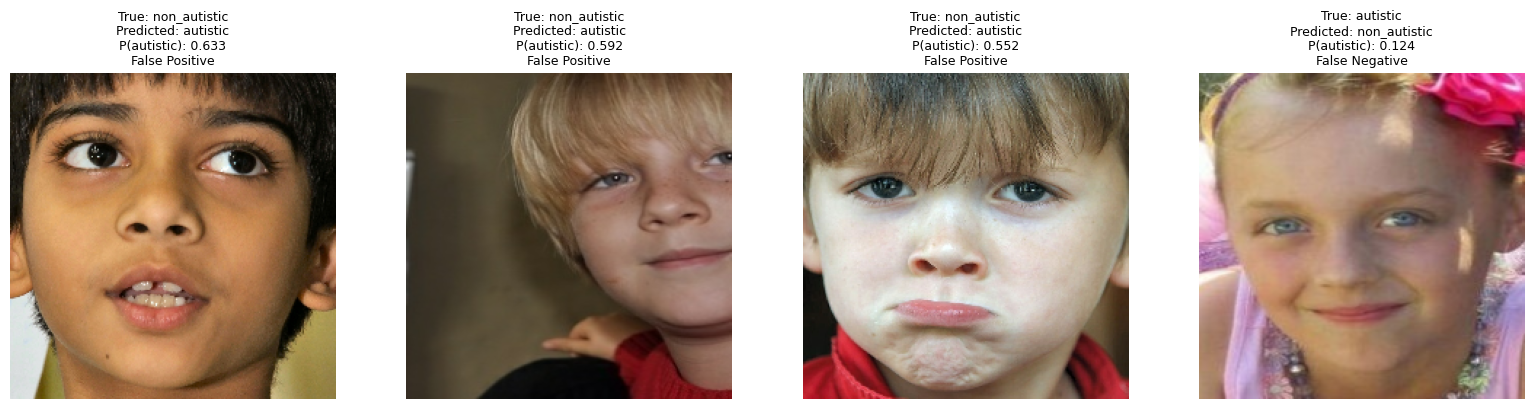

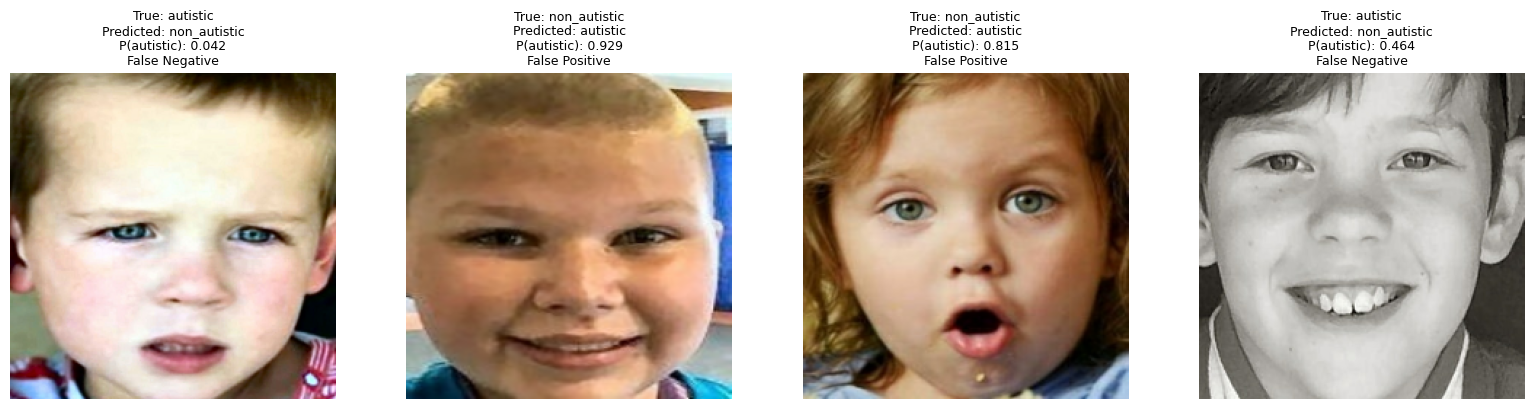

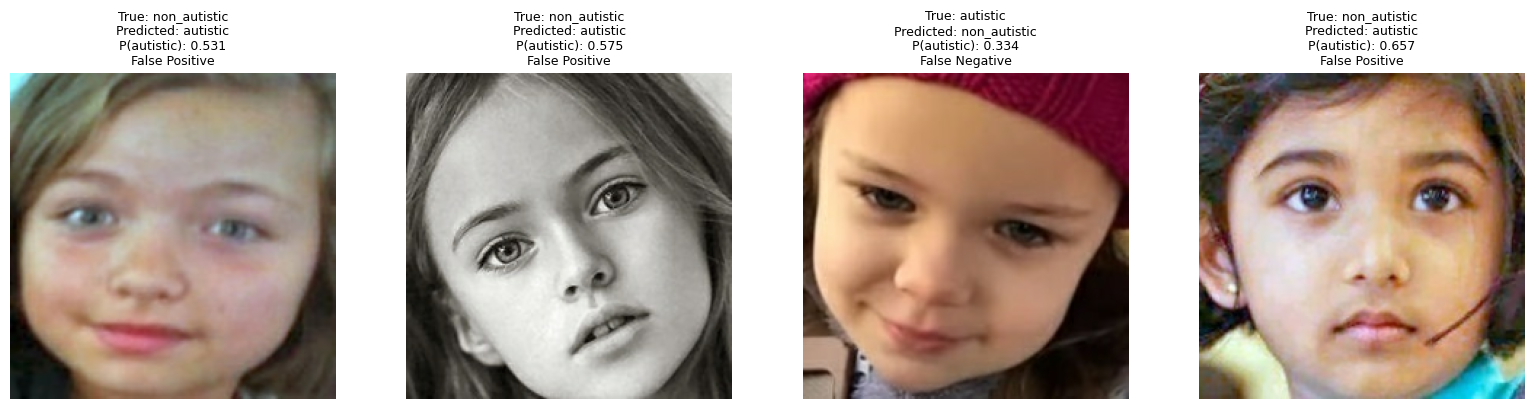

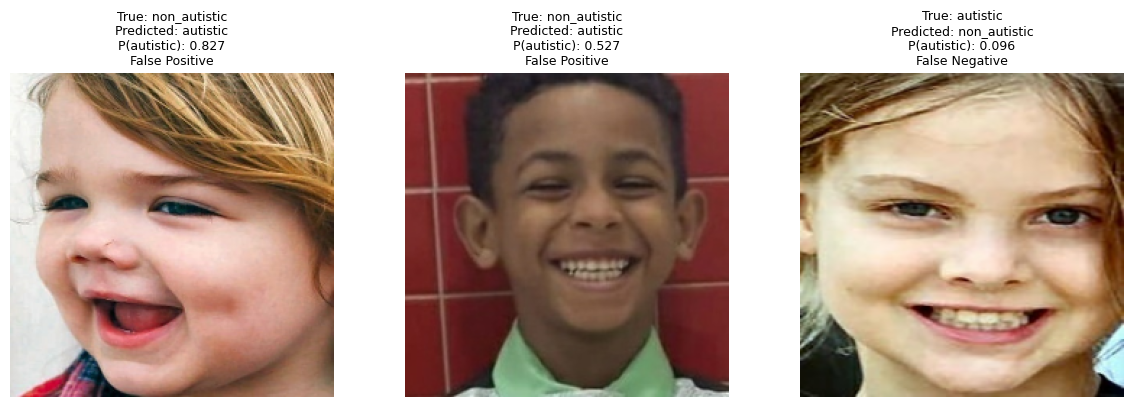


Note: These are validation images. Do not use the test set to choose or tune the model.


In [ ]:
# %% Cell 14: Analyze Misclassified Validation Images

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

from sklearn.metrics import confusion_matrix

# Load the original baseline model
model = keras.models.load_model(
    "/kaggle/working/vit_finetuned.keras"
)

# Collect validation images and their true labels
images_list = []
labels_list = []

for images, labels in val_ds:
    images_list.append(images.numpy())
    labels_list.append(labels.numpy().reshape(-1))

X_val = np.concatenate(images_list, axis=0)
y_val = np.concatenate(labels_list, axis=0).astype(int)

# Predict probabilities
probabilities = model.predict(
    X_val,
    batch_size=32,
    verbose=1
).reshape(-1)

# Standard classification threshold
threshold = 0.5
y_pred = (probabilities >= threshold).astype(int)

# Find incorrect predictions
wrong_indices = np.where(y_pred != y_val)[0]

print("Validation images:", len(y_val))
print("Incorrect predictions:", len(wrong_indices))
print("Accuracy:", round(np.mean(y_pred == y_val), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred))

# Show incorrectly classified images
if len(wrong_indices) == 0:
    print("No misclassified images found.")
else:
    images_per_row = 4
    max_images = min(len(wrong_indices), 24)

    for start in range(0, max_images, images_per_row):
        batch_indices = wrong_indices[
            start:start + images_per_row
        ]

        fig, axes = plt.subplots(
            1,
            len(batch_indices),
            figsize=(4 * len(batch_indices), 4)
        )

        if len(batch_indices) == 1:
            axes = [axes]

        for ax, idx in zip(axes, batch_indices):
            # Convert model input from [-1, 1] to [0, 1]
            image = np.clip(
                (X_val[idx] + 1.0) / 2.0,
                0,
                1
            )

            true_label = (
                "autistic" if y_val[idx] == 1
                else "non_autistic"
            )

            predicted_label = (
                "autistic" if y_pred[idx] == 1
                else "non_autistic"
            )

            error_type = (
                "False Positive"
                if y_val[idx] == 0 and y_pred[idx] == 1
                else "False Negative"
            )

            ax.imshow(image)
            ax.set_title(
                f"True: {true_label}\n"
                f"Predicted: {predicted_label}\n"
                f"P(autistic): {probabilities[idx]:.3f}\n"
                f"{error_type}",
                fontsize=9
            )
            ax.axis("off")

        plt.tight_layout()
        plt.show()

print(
    "\nNote: These are validation images. "
    "Do not use the test set to choose or tune the model."
)

In [ ]:


import os

BASE_DIR = "/kaggle/input/datasets/prayashdas/autistic-children-facial-image-dataset"

splits = {
    "Train": os.path.join(BASE_DIR, "train"),
    "Original Validation": os.path.join(BASE_DIR, "valid"),
    "Original Test": os.path.join(BASE_DIR, "test")
}

extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

counts = {}

for split_name, folder in splits.items():
    total = 0

    for root, dirs, files in os.walk(folder):
        total += sum(
            1 for file in files
            if file.lower().endswith(extensions)
        )

    counts[split_name] = total
    print(f"{split_name}: {total} images")

print("\nNote: These are the original folder counts.")

Train: 2526 images
Original Validation: 200 images
Original Test: 200 images

Note: These are the original folder counts.
